# 09. UPI Fraud Prediction — Modified and Data-Checked

**Logistic Regression vs Decision Tree vs Random Forest**

This notebook keeps Notebook 09’s original goal: compare three classification algorithms. It is adjusted to work with the files in `C:\UPI Data` and only use columns that actually exist in the raw UPI CSV.

**Important data limitations**
- The original dataset has 10,000 rows and 16 columns, including 99 fraud-labelled transactions.
- `Transaction_Date` contains a date only, not a transaction time. This notebook therefore does not create an `Hour` feature.
- The source data has no actual device type, new-device flag, merchant category, or new-beneficiary flag, so those features are not used.
- `Transaction_Status` and `Failure_Reason` are excluded from predictors because they may reveal transaction outcomes or information unavailable at decision time.
- This is a prototype on a dataset labelled as synthetic, not a production payment-fraud detector.


In [16]:
from pathlib import Path
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report
)

RANDOM_STATE = 42
DATA_DIR = Path(r"C:\UPI Data")
OUTPUT_DIR = DATA_DIR / "outputs"
MODEL_DIR = DATA_DIR / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")
print("Output folder:", OUTPUT_DIR)
print("Model folder:", MODEL_DIR)

Libraries imported successfully.
Output folder: C:\UPI Data\outputs
Model folder: C:\UPI Data\models


## 1. Load the dataset

The cleaned CSV is tried first. If it is not present, the notebook falls back to the raw CSV. The selected columns are validated below, so extra columns in a cleaned file will not accidentally introduce unsupported features.

In [17]:

possible_paths = [
    Path(r"C:\UPI Data\UPI_Transactions_Cleaned.csv"),
    Path(r"C:\UPI Data\UPI_Transactions_Raw.csv"),
]

# Find the first CSV file that exists
DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find C:/UPI Data/UPI_Transactions_Cleaned.csv "
        "or C:/UPI Data/UPI_Transactions_Raw.csv. "
        "Check the folder and filenames."
    )

# Load the dataset
df = pd.read_csv(DATA_PATH)

print("Loaded:", DATA_PATH)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

# Check required columns
required_columns = [
    "Transaction_Date",
    "City",
    "State",
    "Sender_Bank",
    "Receiver_Bank",
    "UPI_App",
    "Transaction_Type",
    "Payment_Method",
    "Amount",
    "Processing_Time_sec",
    "Bank_Response_Time_ms",
    "Fraud_Label"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Dataset is missing required columns: {missing_columns}"
    )

# Validate and standardize the fraud labels
df["Fraud_Label"] = pd.to_numeric(
    df["Fraud_Label"], errors="coerce"
)

df = df.dropna(subset=["Fraud_Label"]).copy()

if not set(df["Fraud_Label"].unique()).issubset({0, 1}):
    raise ValueError(
        "Fraud_Label must contain only 0 (non-fraud) "
        "and 1 (fraud)."
    )

df["Fraud_Label"] = df["Fraud_Label"].astype(int)

# Display fraud counts and fraud rate
print("\nFraud counts:")
print(df["Fraud_Label"].value_counts().sort_index())

print(
    "\nFraud rate: {:.2f}%".format(
        df["Fraud_Label"].mean() * 100
    )
)


Loaded: C:\UPI Data\UPI_Transactions_Cleaned.csv
Dataset shape: (10000, 24)
Columns: ['Transaction_ID', 'Transaction_Date', 'Customer_ID', 'City', 'State', 'Sender_Bank', 'Receiver_Bank', 'UPI_App', 'Transaction_Type', 'Payment_Method', 'Amount', 'Transaction_Status', 'Failure_Reason', 'Processing_Time_sec', 'Bank_Response_Time_ms', 'Fraud_Label', 'Year', 'Month', 'Month_Name', 'Day', 'Day_of_Week', 'Day_of_Week_Num', 'Is_Weekend', 'Quarter']

Fraud counts:
Fraud_Label
0    9901
1      99
Name: count, dtype: int64

Fraud rate: 0.99%


## 2. Create valid predictors

We derive calendar fields from `Transaction_Date` only. There is no hour-of-day information in the source. IDs and outcome-related columns are not predictors.

In [18]:
df["Transaction_Date"] = pd.to_datetime(df["Transaction_Date"], errors="coerce")
df["Transaction_Month"] = df["Transaction_Date"].dt.month
df["Transaction_Day"] = df["Transaction_Date"].dt.day
df["Day_of_Week_Num"] = df["Transaction_Date"].dt.dayofweek
df["Is_Weekend"] = df["Day_of_Week_Num"].isin([5, 6]).astype("int64")
df["Transaction_Quarter"] = df["Transaction_Date"].dt.quarter

# Only columns present in the original dataset plus valid date-derived features.
categorical_features = [
    "City", "State", "Sender_Bank", "Receiver_Bank", "UPI_App",
    "Transaction_Type", "Payment_Method"
]
numerical_features = [
    "Amount", "Processing_Time_sec", "Bank_Response_Time_ms",
    "Transaction_Month", "Transaction_Day", "Day_of_Week_Num",
    "Is_Weekend", "Transaction_Quarter"
]
feature_columns = categorical_features + numerical_features
X = df[feature_columns].copy()
y = df["Fraud_Label"].copy()

print("Categorical predictors:", categorical_features)
print("Numerical predictors:", numerical_features)
print("\nExcluded from predictors: Transaction_ID, Customer_ID, Transaction_Date, Transaction_Status, Failure_Reason, Fraud_Label")
print("Unsupported features not used: Hour, Merchant_Category, Device_Type, Is_New_Device, Is_New_Beneficiary")

Categorical predictors: ['City', 'State', 'Sender_Bank', 'Receiver_Bank', 'UPI_App', 'Transaction_Type', 'Payment_Method']
Numerical predictors: ['Amount', 'Processing_Time_sec', 'Bank_Response_Time_ms', 'Transaction_Month', 'Transaction_Day', 'Day_of_Week_Num', 'Is_Weekend', 'Transaction_Quarter']

Excluded from predictors: Transaction_ID, Customer_ID, Transaction_Date, Transaction_Status, Failure_Reason, Fraud_Label
Unsupported features not used: Hour, Merchant_Category, Device_Type, Is_New_Device, Is_New_Beneficiary


## 3. Split the data and prepare preprocessing

A stratified 80/20 split preserves the approximate fraud proportion in both sets. All imputation, scaling, and one-hot encoding are fitted inside each model pipeline using training data only.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training rows: {len(X_train):,}; fraud cases: {int(y_train.sum())}")
print(f"Testing rows:  {len(X_test):,}; fraud cases: {int(y_test.sum())}")

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

Training rows: 8,000; fraud cases: 79
Testing rows:  2,000; fraud cases: 20


## 4. Train and compare three algorithms

The main comparison remains Logistic Regression, Decision Tree, and Random Forest. A majority-class dummy baseline is also included as a reference. Because fraud is rare, do not judge the models by accuracy alone; pay attention to fraud recall, precision, F1, ROC-AUC, and PR-AUC.

In [20]:
models = {
    "Dummy Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(
        criterion="entropy", max_depth=8, min_samples_split=10,
        min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=12, min_samples_split=10,
        min_samples_leaf=3, class_weight="balanced_subsample",
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

trained_models = {}
predictions = {}
probabilities = {}
results = []

for model_name, classifier in models.items():
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", classifier)])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    if hasattr(pipeline, "predict_proba"):
        y_prob = pipeline.predict_proba(X_test)[:, 1]
    else:
        y_prob = y_pred.astype(float)

    trained_models[model_name] = pipeline
    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Fraud_Precision": precision_score(y_test, y_pred, zero_division=0),
        "Fraud_Recall": recall_score(y_test, y_pred, zero_division=0),
        "Fraud_F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_prob),
        "PR_AUC_Average_Precision": average_precision_score(y_test, y_prob),
    })

comparison = pd.DataFrame(results).sort_values("PR_AUC_Average_Precision", ascending=False)
display(comparison.round(4))

,Model,Accuracy,Fraud_Precision,Fraud_Recall,Fraud_F1,ROC_AUC,PR_AUC_Average_Precision
1,Logistic Regression,0.6805,0.0156,0.50,0.0303,0.5791,0.0223
3,Random Forest,0.9900,0.0000,0.00,0.0000,0.5116,0.0212
2,Decision Tree,0.7875,0.0120,0.25,0.0230,0.5116,0.0104
0,Dummy Baseline,0.9900,0.0000,0.00,0.0000,0.5000,0.0100


In [21]:

# Save the comparison table for documentation and Power BI use.
comparison_path = OUTPUT_DIR / "ML_Model_Comparison.csv"
comparison.to_csv(comparison_path, index=False)
print("Saved model comparison to:", comparison_path)

# Save each complete pipeline as a .joblib file.
# Each pipeline includes preprocessing + classifier.
# A separate scaler file is not required.

for model_name, pipeline in trained_models.items():
    safe_name = {
        "Dummy Baseline": "fraud_dummy",
        "Logistic Regression": "fraud_logistic_regression",
        "Decision Tree": "fraud_decision_tree",
        "Random Forest": "fraud_rf",
    }[model_name]

    model_path = MODEL_DIR / f"{safe_name}.joblib"
    joblib.dump(pipeline, model_path)

    print("Saved:", model_path)


Saved model comparison to: C:\UPI Data\outputs\ML_Model_Comparison.csv
Saved: C:\UPI Data\models\fraud_dummy.joblib
Saved: C:\UPI Data\models\fraud_logistic_regression.joblib
Saved: C:\UPI Data\models\fraud_decision_tree.joblib
Saved: C:\UPI Data\models\fraud_rf.joblib


## 5. Review fraud-class performance

The confusion matrix shows true negatives, false positives, false negatives, and true positives. In fraud analytics, false positives can inconvenience legitimate users, while false negatives are missed fraud cases.

In [22]:
# Select the best model by PR-AUC for a descriptive follow-up.
best_model_name = comparison.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = predictions[best_model_name]

print("Highest test PR-AUC in this comparison:", best_model_name)
print("\nClassification report:")
print(classification_report(y_test, best_predictions, labels=[0, 1], target_names=["Not fraud", "Fraud"], zero_division=0))
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, best_predictions, labels=[0, 1]))

Highest test PR-AUC in this comparison: Logistic Regression

Classification report:
              precision    recall  f1-score   support

   Not fraud       0.99      0.68      0.81      1980
       Fraud       0.02      0.50      0.03        20

    accuracy                           0.68      2000
   macro avg       0.50      0.59      0.42      2000
weighted avg       0.98      0.68      0.80      2000

Confusion matrix [[TN, FP], [FN, TP]]:
[[1351  629]
 [  10   10]]


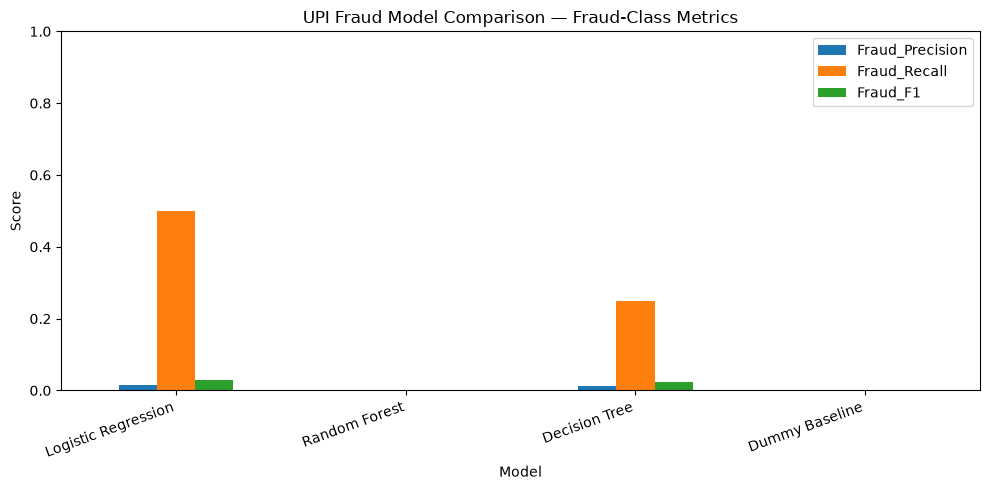

In [23]:
# Plot a readable comparison of fraud recall and precision.
plot_metrics = comparison.set_index("Model")[["Fraud_Precision", "Fraud_Recall", "Fraud_F1"]]
ax = plot_metrics.plot(kind="bar", figsize=(10, 5))
ax.set_title("UPI Fraud Model Comparison — Fraud-Class Metrics")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 6. Example prediction

This example predicts one held-out transaction. The score is a model output, not a real payment decision or a guarantee that a transaction is fraudulent.

In [24]:
example_row = X_test.iloc[[0]].copy()
example_probability = best_model.predict_proba(example_row)[0, 1]
example_prediction = int(best_model.predict(example_row)[0])

print("Model:", best_model_name)
print("Predicted class:", "Fraud" if example_prediction == 1 else "Not fraud")
print(f"Estimated model probability for fraud: {example_probability:.3f}")
print("This is a model score on labelled dataset data, not a real payment decision.")

Model: Logistic Regression
Predicted class: Fraud
Estimated model probability for fraud: 0.729
This is a model score on labelled dataset data, not a real payment decision.


## 7. Interpretation and limitations

- A high accuracy score can be misleading because about 99% of rows are non-fraud.
- Precision and recall trade off: flagging more transactions may catch more fraud but can also create more false alarms.
- These results are specific to this dataset and this random split; they do not establish production performance.
- No hour-of-day, device, merchant-category, or new-beneficiary conclusions should be made from this source CSV because those fields are not present.
- The saved `.pkl` files contain full pipelines, including the scaler and categorical encoders. Load only files you created or otherwise trust.
